# Semana 7 — Estatística descritiva e EDA

Nesta semana a análise usa **somente os sete lançamentos presentes em `despesas_clean` no SQLite recebido**. Calculo medidas centrais, dispersão, composição por categoria e UF, e verifico o peso do registro de R$ 5.000,00.

O banco contém apenas setembro de 2026, então não é possível estudar tendência de meses ou sazonalidade.


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

# Funciona ao executar o notebook pela raiz do projeto ou pela pasta da semana.
def encontrar_raiz():
    for p in (Path.cwd(), Path.cwd().parent):
        if (p / 'semana_10_app_streamlit' / 'fintech_integrada.db').is_file():
            return p.resolve()
    raise FileNotFoundError('Não encontrei semana_10_app_streamlit/fintech_integrada.db.')

RAIZ = encontrar_raiz()
BANCO = RAIZ / 'semana_10_app_streamlit' / 'fintech_integrada.db'
conexao = sqlite3.connect(f'file:{BANCO}?mode=ro', uri=True)
conexao.execute('PRAGMA foreign_keys=ON')
print('Banco utilizado:', BANCO.name)
print('Integridade:', conexao.execute('PRAGMA integrity_check').fetchone()[0])


Banco utilizado: fintech_integrada.db
Integridade: ok


In [2]:
consulta = """
    SELECT d.id,d.valor,d.data,d.estudante_id,d.municipio_id,
           d.categoria,d.is_outlier,
           e.nome AS estudante,e.matricula,m.nome AS municipio,m.uf_sigla AS uf
    FROM despesas_clean AS d
    INNER JOIN estudantes AS e ON e.id=d.estudante_id
    INNER JOIN municipios AS m ON m.id=d.municipio_id
    ORDER BY d.data,d.id
"""
despesas = pd.read_sql_query(consulta,conexao,parse_dates=['data'])
despesas['is_outlier'] = despesas['is_outlier'].fillna(0).astype(bool)
display(despesas)


,id,valor,data,estudante_id,municipio_id,categoria,is_outlier,estudante,matricula,municipio,uf
0,1,125.9,2026-09-01,1,3500105,alimentação,False,Ana Souza,2026001,Adamantina,SP
1,2,89.5,2026-09-02,2,3300100,transporte,False,Bruno Lima,2026002,Angra dos Reis,RJ
2,3,210.0,2026-09-03,3,3100104,lazer,False,Carla Mendes,2026003,Abadia dos Dourados,MG
3,4,107.7,2026-09-07,1,3500105,alimentação,False,Ana Souza,2026001,Adamantina,SP
4,5,75.0,2026-09-08,1,3500105,nao_informado,False,Ana Souza,2026001,Adamantina,SP
5,6,5000.0,2026-09-09,1,3500105,transporte,True,Ana Souza,2026001,Adamantina,SP
6,7,64.9,2026-09-10,1,3500105,lazer,False,Ana Souza,2026001,Adamantina,SP


## Média, mediana, desvio padrão e coeficiente de variação


In [3]:
valores=despesas.valor
soma=float(valores.sum())
resumo=pd.Series({
    'despesas (n)':len(valores),'total (R$)':soma,'média (R$)':valores.mean(),
    'mediana (R$)':valores.median(),'desvio padrão amostral (R$)':valores.std(ddof=1),
    'coeficiente de variação (%)':100*valores.std(ddof=1)/valores.mean(),
    'mínimo (R$)':valores.min(),'máximo (R$)':valores.max(),
    'assimetria (Fisher)':valores.skew(),
})
display(resumo.to_frame('resultado').round(2))


,resultado
despesas (n),7.00
total (R$),5673.00
média (R$),810.43
mediana (R$),107.70
desvio padrão amostral (R$),1848.05
coeficiente de variação (%),228.03
mínimo (R$),64.90
máximo (R$),5000.00
assimetria (Fisher),2.64


## O efeito do outlier na média

A média de todos os lançamentos e a média sem o valor atípico respondem a perguntas diferentes. Não removo a despesa da fonte; apenas comparo os cenários.


In [4]:
sem_outlier=despesas.loc[~despesas.is_outlier]
comparacao=pd.DataFrame({
    'cenário':['Todas as despesas','Somente despesas não sinalizadas'],
    'registros':[len(despesas),len(sem_outlier)],
    'total':[despesas.valor.sum(),sem_outlier.valor.sum()],
    'média':[despesas.valor.mean(),sem_outlier.valor.mean()],
    'mediana':[despesas.valor.median(),sem_outlier.valor.median()],
})
display(comparacao.round(2))
valor_outlier=despesas.loc[despesas.is_outlier,'valor'].sum()
print(f'A(s) despesa(s) atípica(s) representam {100*valor_outlier/soma:.2f}% do total.')


,cenário,registros,total,média,mediana
0,Todas as despesas,7,5673.0,810.43,107.7
1,Somente despesas não sinalizadas,6,673.0,112.17,98.6


A(s) despesa(s) atípica(s) representam 88.14% do total.


## Agrupamento por categoria, estudante e UF


In [5]:
por_categoria=despesas.groupby('categoria').agg(
    registros=('valor','size'),total=('valor','sum'),media=('valor','mean'),
    desvio=('valor','std')).sort_values('total',ascending=False)
por_categoria['participacao_%']=(100*por_categoria.total/soma).round(2)
por_categoria['cv_%']=(100*por_categoria.desvio/por_categoria.media).round(2)
display(por_categoria.round(2))
por_estudante=despesas.groupby('estudante').valor.agg(['count','sum','mean','median']).sort_values('sum',ascending=False)
display(por_estudante.round(2))
por_uf=despesas.groupby('uf').valor.agg(['count','sum','mean']).sort_values('sum',ascending=False)
display(por_uf.round(2))


,registros,total,media,desvio,participacao_%,cv_%
categoria,,,,,,
transporte,2,5089.5,2544.75,3472.25,89.71,136.45
lazer,2,274.9,137.45,102.60,4.85,74.65
alimentação,2,233.6,116.80,12.87,4.12,11.02
nao_informado,1,75.0,75.00,NaN,1.32,NaN


,count,sum,mean,median
estudante,,,,
Ana Souza,5,5373.5,1074.7,107.7
Carla Mendes,1,210.0,210.0,210.0
Bruno Lima,1,89.5,89.5,89.5


,count,sum,mean
uf,,,
SP,5,5373.5,1074.7
MG,1,210.0,210.0
RJ,1,89.5,89.5


## Visualização da distribuição


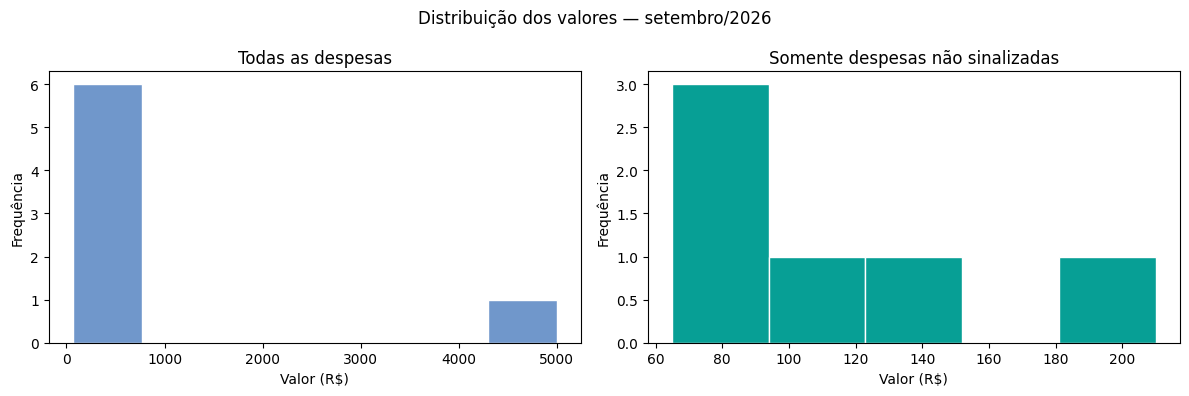

In [6]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(despesas.valor,bins=7,color='#7097CB',edgecolor='white')
axes[0].set(title='Todas as despesas',xlabel='Valor (R$)',ylabel='Frequência')
axes[1].hist(sem_outlier.valor,bins=5,color='#079F95',edgecolor='white')
axes[1].set(title='Somente despesas não sinalizadas',xlabel='Valor (R$)',ylabel='Frequência')
fig.suptitle('Distribuição dos valores — setembro/2026')
fig.tight_layout()
plt.show()


## Correlação: limite da amostra

Como há somente três UFs com despesas e uma delas tem apenas um lançamento, uma correlação por estado seria matematicamente instável e fácil de interpretar de forma errada. Por esse motivo, apresento agrupamentos descritivos, **sem usar correlação para sustentar conclusões de negócio**.


In [7]:
display(Markdown(
    f'**Leitura dos dados:** foram **{len(despesas)} despesas**, totalizando **R$ {soma:,.2f}**, '
    f'com mediana de **R$ {valores.median():,.2f}**. '
    f'Uma despesa concentra **{100*valor_outlier/soma:.2f}%** do total; '
    f'sem ela, a média cai de **R$ {valores.mean():,.2f}** para **R$ {sem_outlier.valor.mean():,.2f}**. '
    'Os valores não representam o perfil de gastos de uma população de estudantes.'
))
conexao.close()


**Leitura dos dados:** foram **7 despesas**, totalizando **R$ 5,673.00**, com mediana de **R$ 107.70**. Uma despesa concentra **88.14%** do total; sem ela, a média cai de **R$ 810.43** para **R$ 112.17**. Os valores não representam o perfil de gastos de uma população de estudantes.

## Conclusão

A média de R$ 810,43 sozinha não representa bem as despesas usuais porque o gasto atípico domina a distribuição. A mediana e a comparação sem outliers ajudam na leitura, mas a base é muito pequena para extrapolações ou generalizações.
